In [1]:
"""
Food at home (CUSR0000SAF11): unit roots, ACF / PACF, candidate models, selection and
diagnostics, using the functions in pipeline.py.

Inputs : data/raw/fred_prices_raw.csv
Outputs: none (tables and figures shown inline; my readings in the markdown cells)
"""
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

import pipeline as pl
# pipeline.py sets a files-only backend; this line makes figures show in the notebook
%matplotlib inline

# Series to work on (headline CPI is done in fit_headline_cpi.ipynb):
# CPILFESL core CPI | PCEPI PCE | CUSR0000SAF11 food at home
# CPIENGSL energy | CUSR0000SEHF energy services | CUSR0000SETB01 gasoline | CUSR0000SEHF01 electricity
SID = "CUSR0000SAF11"

NONE = (0, 0, 0, 0)    # no seasonal terms
SMA = (0, 0, 1, 12)    # seasonal MA(1) at lag 12

prices_raw = pl.load_prices()
level, filled = pl.step1_prepare(prices_raw, SID)
pi = pl.step3_inflation(level)
pi_train, pi_test = pl.split(pi)
level_train = level.loc[pl.SAMPLE_START:pl.TRAIN_END]
print(f"{SID}: {len(pi_train)} training months, {len(pi_test)} hold-out months; filled: {filled}")

CUSR0000SAF11: 468 training months, 32 hold-out months; filled: ['2025-10']


## Step 1. The price level: is it a unit-root series?

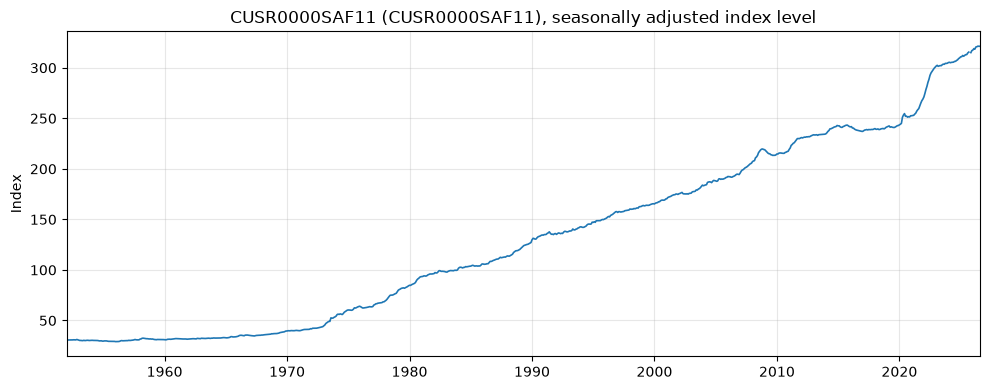

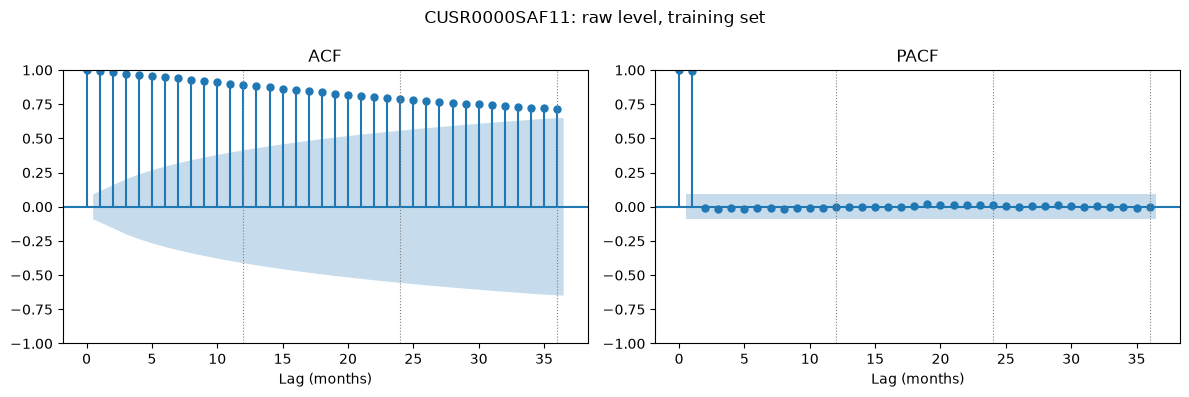

,ADF stat,ADF p,ADF lags,KPSS stat,KPSS p,KPSS bandwidth
Deterministic spec,,,,,,
Constant + trend,-3.427320,0.047843,17,0.104892,0.10,12
Constant only,0.714074,0.990115,14,3.633154,0.01,12


In [2]:
pl.fig_raw_level(prices_raw, SID, SID)
pl.fig_acf_pacf(level_train, f"{SID}: raw level, training set")
plt.show()   # draw the figures before the table
display(pl.unit_root_table(level_train, ("ct", "c")))

- Yes, the level trends. Both tests agree: constant + trend is trend-stationary (ADF p = 0.048, borderline; KPSS p ≥ 0.10), and constant-only shows a unit root.
- Project examines inflation, will difference and transform series.
- Inflation is stationary and there is risk of overdifferencing. This can be checked with ACF.

## Step 2. Inflation: stationary, or difference again?

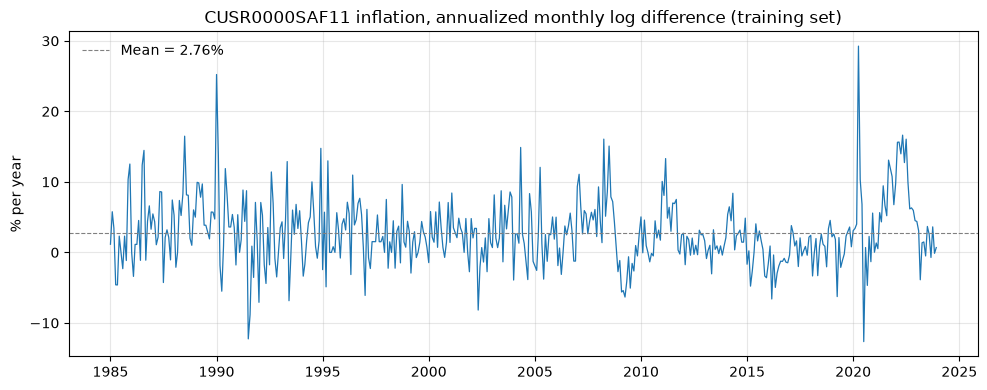

,ADF stat,ADF p,ADF lags,KPSS stat,KPSS p,KPSS bandwidth
Deterministic spec,,,,,,
Constant only,-3.812474,0.002782,16,0.158411,0.1,9
Constant + trend,-3.851783,0.014116,16,0.110495,0.1,9


In [3]:
pl.fig_inflation(pi_train, SID)
plt.show()   # draw the figures before the table
display(pl.unit_root_table(pi_train, ("c", "ct")))

- Inflation is stationary at d = 0. 
- ADF rejects a unit root in both specs (constant only p = 0.003, constant + trend p = 0.014)
- KPSS does not reject stationarity (p ≥ 0.10, the upper bound of its table). 
- The tests agree, so I model inflation with d = 0.

In [4]:
D = 0   # YOUR CHOICE: 0 = model inflation, 1 = model the change in inflation
y = pi_train if D == 0 else pi_train.diff().dropna()
if D == 1:
    display(pl.unit_root_table(y, ("c", "ct")))

## Step 3. Identification: what do the ACF and PACF suggest?

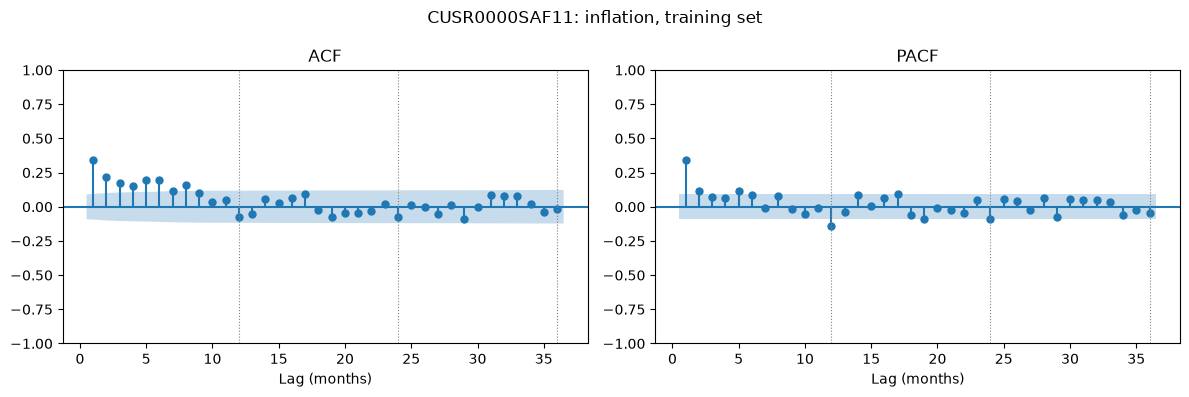

In [5]:
pl.fig_acf_pacf(y, f"{SID}: {'inflation' if D == 0 else 'change in inflation'}, training set", zero=False);

- ACF decays to about lag 10, random afterwards.
- PACF large spike at lag 1, small decay to lag 5, random afterwards.
- Candidates: AR(1), AR on 1 and 5, ARMA(1,1)
- Added after Step 4: AR(1,2,5,12) and ARMA(1,1)xSMA(1), because Ljung-Box failed at lags 12 and 24 (seasonal leftover).

In [6]:
# YOUR CANDIDATES. Orders are (p, d, q) with d = D; seasonal is NONE or SMA. Examples:
#   "AR(1)": ((1, D, 0), NONE)      "MA(1)": ((0, D, 1), NONE)
#   "ARMA(1,1)": ((1, D, 1), NONE)  "ARMA(1,1)xSMA(1)": ((1, D, 1), SMA)
#   subset AR with only lags 2 and 5: (([2, 5], D, 0), NONE)
candidates = {
    "AR(1)": ((1, D, 0), NONE),
    "AR(1,2,5)": (([1, 2, 5], D, 0), NONE),
    "AR(1,2,5,12)": (([1, 2, 5, 12], D, 0), NONE),
    "ARMA(1,1)": ((1, D, 1), NONE),
    "ARMA(1,1)xSMA(1)": ((1, D, 1), SMA)
}

## Step 4. Estimate and compare

In [7]:
fits = pl.step7_estimate(pi_train, candidates)
display(pl.step7_table(fits, candidates))

AR(1)       AR(1,2,5)  \
Block                    Statistic                                         
Coefficients             const             2.758 (0.000)   2.744 (0.000)   
                         sigma2           20.420 (0.000)  19.736 (0.000)   
                         ar.L1             0.339 (0.000)   0.285 (0.000)   
                         ar.L2                             0.098 (0.024)   
                         ar.L5                             0.135 (0.001)   
                         ar.L12                                            
                         ma.L1                                             
                         ma.S.L12                                          
Fit                      Log-lik                 -1370.0         -1362.1   
                         AIC                      2746.0          2734.2   
                         BIC                      2758.4          2754.9   
                         HQIC                     2750.9          2742.3   
Residual diagnostics (p) Ljung-Box(6) p            0.000           0.173   
                         Ljung-Box(12) p           0.000           0.066   
                         Ljung-Box(24) p           0.000           0.008   
                         Jarque-Bera p             0.000           0.000   

                                            AR(1,2,5,12)       ARMA(1,1)  \
Block                    Statistic                                         
Coefficients             const             2.756 (0.000)   2.743 (0.000)   
                         sigma2           19.458 (0.000)  19.849 (0.000)   
                         ar.L1             0.288 (0.000)   0.827 (0.000)   
                         ar.L2             0.099 (0.023)                   
                         ar.L5             0.149 (0.000)                   
                         ar.L12           -0.110 (0.006)                   
                         ma.L1                            -0.602 (0.000)   
                         ma.S.L12                                          
Fit                      Log-lik                 -1358.8         -1363.4   
                         AIC                      2729.7          2734.8   
                         BIC                      2754.6          2751.4   
                         HQIC                     2739.5          2741.3   
Residual diagnostics (p) Ljung-Box(6) p            0.046           0.089   
                         Ljung-Box(12) p           0.193           0.050   
                         Ljung-Box(24) p           0.019           0.003   
                         Jarque-Bera p             0.000           0.000   

                                         ARMA(1,1)xSMA(1)  
Block                    Statistic                         
Coefficients             const              2.741 (0.000)  
                         sigma2            19.319 (0.000)  
                         ar.L1              0.892 (0.000)  
                         ar.L2                             
                         ar.L5                             
                         ar.L12                            
                         ma.L1             -0.692 (0.000)  
                         ma.S.L12          -0.196 (0.000)  
Fit                      Log-lik                  -1357.3  
                         AIC                       2724.6  
                         BIC                       2745.4  
                         HQIC                      2732.8  
Residual diagnostics (p) Ljung-Box(6) p             0.034  
                         Ljung-Box(12) p            0.247  
                         Ljung-Box(24) p            0.038  
                         Jarque-Bera p              0.000

- AIC, BIC, HQIC prefer ARMAxSMA model
- Reject LB @ lags 6,24 at 5% significance level -> autocorrelation, but fail to reject at 1%
- Fail to reject LB @ 12 -> no autocorrelation
- const 2.741 -> long run mean of inflation ~2.7% a year
- Variance (sigma2) ~ 19.3 -> standard deviation ~ 4.4
- AR L1 persistance 0.89 high
- MA L1 -0.69 reverse/ bounce back
- MA S L12 -0.20 reverse/ bounce back
- Log-lik highest (least negative)
- [TO CHECK] Choice: all three criteria prefer ARMA(1,1)xSMA(1) (ΔBIC = 6 over ARMA(1,1)), and it removes the lag-12 correlation.

## Step 5. Diagnostics of your chosen model

In [8]:
SELECTED = "ARMA(1,1)xSMA(1)"
order, seasonal = candidates[SELECTED]
diag, roots = pl.step8_diagnostics(fits[SELECTED], pl.n_arma(order, seasonal))
display(diag.round(4), roots.round(3))

,Checks,Statistic,p-value
Test,,,
Ljung-Box(6),Serial correlation,8.6437,0.0344
Ljung-Box(12),Serial correlation,11.4433,0.2465
Ljung-Box(24),Serial correlation,33.7730,0.0383
Jarque-Bera,"Normality (skew 0.53, kurtosis 7.3)",370.2351,0.0000


,Modulus,Outside unit circle
AR root 1,1.121,True
MA root 1,1.146,True
MA root 2,1.146,True
MA root 3,1.146,True
MA root 4,1.146,True
MA root 5,1.146,True
MA root 6,1.146,True
MA root 7,1.146,True
MA root 8,1.146,True
MA root 9,1.146,True


- Fail to reject LB @ lag 12 -> no evidence of autocorrelation
- Reject LB @ lags 6, 24 at the 5% significance level (p = 0.034, 0.038) but not at 1% -> mild leftover autocorrelation
- Reject JB -> non normal distribution (fat tails, kurtosis 7.3; right skew 0.53)
- AR roots > 1 -> stationary
- MA roots > 1 -> Invertible

Final choice: ARMA(1,1)xSMA(1). It has the best AIC, BIC and HQIC, the seasonal term removes the lag-12 correlation, only mild correlation remains at lags 6 and 24 (passes at 1%), and it is stationary and invertible.

## Step 6. Structural breaks at the known dates

In [9]:
# Mean, persistence (AR(1)), Chow and variance tests at COVID-19, the 2025 tariffs and the
# Iran conflict, on the full sample (training + hold-out)
known = pl.step10_known(pi)
display(known.round(3))

# The selected model estimated before and after COVID, and the LR test of one parameter set
regimes, lr = pl.step10_regimes(pi, order, seasonal)
display(regimes)
print(f"LR = {lr['LR']:.2f}, df = {lr['df']}, p = {lr['p']:.4f}")

,Months after,Mean before,Mean after,Mean shift p,AR(1) before,AR(1) after,Persistence change p,Chow p,Variance ratio,Variance ratio p,Brown-Forsythe p
COVID-19,78,2.439,4.223,0.210,0.257,0.490,0.208,0.242,1.506,0.013,0.324
2025 tariffs,17,2.741,2.046,0.184,0.339,-0.408,0.000,0.000,0.746,0.506,0.829
2026 Iran conflict,7,2.728,2.010,0.256,0.334,-0.554,0.000,0.000,0.933,0.941,0.982


,Start,Months,Converged,Log-lik,const,ar.L1,ma.L1,ma.S.L12,sigma2
Full sample,1985-01,500,True,-1440.0,2.69,0.896,-0.701,-0.203,18.55
Pre-COVID,1985-01,422,True,-1199.6,2.422,0.921,-0.785,-0.213,17.217
Post-COVID,2020-03,78,True,-234.1,4.442,0.868,-0.524,-0.232,23.383


LR = 12.36, df = 5, p = 0.0302


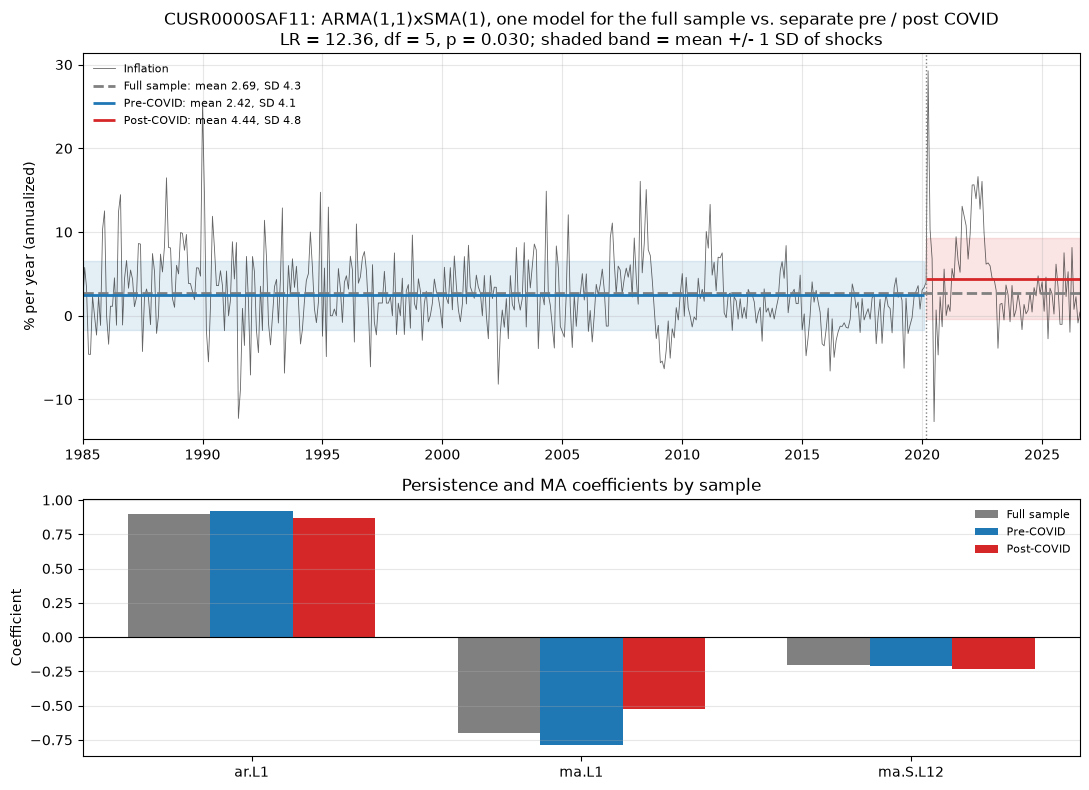

In [10]:
# Full-sample model vs. separate pre- / post-COVID models (the comparison behind the LR test)
covid = pd.Timestamp(pl.BREAK_DATES["COVID-19"])
r = regimes.drop(columns=["Start", "Converged"]).astype(float)
periods = {"Full sample": (pi.index[0], pi.index[-1]),
           "Pre-COVID": (pi.index[0], covid - pd.DateOffset(months=1)),
           "Post-COVID": (covid, pi.index[-1])}
colors = {"Full sample": "gray", "Pre-COVID": "C0", "Post-COVID": "C3"}

fig, axes = plt.subplots(2, 1, figsize=(11, 8), gridspec_kw={"height_ratios": [3, 2]})

# Top: inflation with each model's mean (const) and +/- 1 standard deviation of its shocks
ax = axes[0]
ax.plot(pi.index, pi, color="black", lw=0.6, alpha=0.6, label="Inflation")
for name, (a, b) in periods.items():
    mean, sd = r.loc[name, "const"], r.loc[name, "sigma2"] ** 0.5
    ls = "--" if name == "Full sample" else "-"
    ax.hlines(mean, a, b, color=colors[name], lw=2, ls=ls, label=f"{name}: mean {mean:.2f}, SD {sd:.1f}")
    if name != "Full sample":
        ax.fill_between(pi.loc[a:b].index, mean - sd, mean + sd, color=colors[name], alpha=0.12)
ax.axvline(covid, color="gray", ls=":", lw=1)
ax.set_title(f"{SID}: {SELECTED}, one model for the full sample vs. separate pre / post COVID\n"
             f"LR = {lr['LR']:.2f}, df = {lr['df']}, p = {lr['p']:.3f}; shaded band = mean +/- 1 SD of shocks")
ax.set_ylabel("% per year (annualized)")
ax.set_xlim(pi.index[0], pi.index[-1])
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.grid(alpha=0.3)

# Bottom: the other coefficients side by side
ax = axes[1]
coefs = [c for c in r.columns if c not in ("Months", "Log-lik", "const", "sigma2")]
width = 0.25
for k, name in enumerate(periods):
    ax.bar([j + (k - 1) * width for j in range(len(coefs))], r.loc[name, coefs],
           width, color=colors[name], label=name)
ax.axhline(0, color="black", lw=0.8)
ax.set_xticks(range(len(coefs)), coefs)
ax.set_ylabel("Coefficient")
ax.set_title("Persistence and MA coefficients by sample")
ax.legend(frameon=False, fontsize=8)
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()

COVID (78 months after):
- mean shift up (2.44% -> 4.22%), present but not significant (p = 0.21)
- persistence 0.26 -> 0.49, not significant (p = 0.21)
- chow not significant (p = 0.24)
- variance ratio 1.51 indicates more volatility (F p = 0.013), but Brown-Forsythe does not (p = 0.32): possible volatility increase, not robust (likely a few extreme months)

Tariffs (17 months after):
- mean shift down (2.74% -> 2.05%), not significant (p = 0.18)
- persistence fell from 0.34 to -0.41, significant (p < 0.001): sign flip, inflation zigzags (a high month tends to be followed by a low one)
- chow significant (p < 0.001)
- variance ratio not significant (p = 0.51), nor Brown-Forsythe (p = 0.83)

Iran (7 months after):
- mean shift down (2.73% -> 2.01%), not significant (p = 0.26)
- persistence fell from 0.33 to -0.55, significant (p < 0.001): same zigzag
- chow significant (p < 0.001)
- variance ratio not significant (p = 0.94), nor Brown-Forsythe (p = 0.98)

Caveat: only 17 and 7 months follow the tariff and Iran dates, so these results are suggestive. The tariff window also includes the Iran months, so the two overlap.

Selected model before vs. after COVID (LR test):
- Log Likelihood ratio implies improved fit, suggesting structural break
- mean increase from pre to post
- AR persistance steady
- MA zig zag effect
- Increased varaince

Summary: at COVID, the AR(1) tests find no significant change in mean or persistence (volatility only by the non-robust F test), but the full model's coefficients do differ (LR p = 0.03), mainly a higher mean and larger shocks. After the tariffs and the Iran conflict, persistence turns negative (inflation zigzags month to month), on short samples.

## Step 7. Structural breaks at unknown dates (optional)

### Step 7a. QLR: the single strongest break

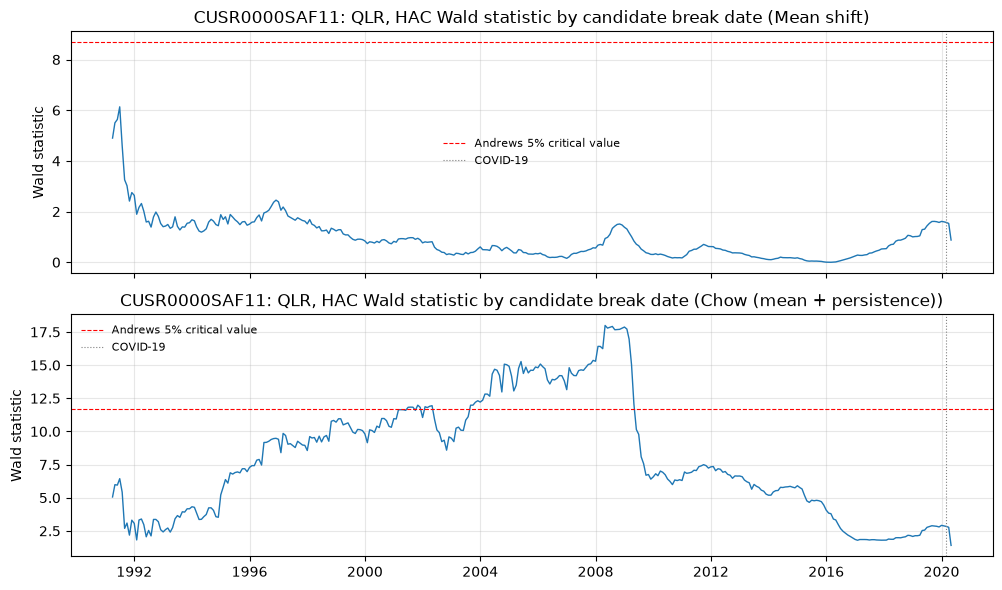

,sup-Wald,Break date,CV 10%,CV 5%,CV 1%,Significant at 5%
Mean shift,6.134877,1991-07,7.12,8.68,12.16,False
Chow (mean + persistence),17.990477,2008-05,10.0,11.72,15.56,True


In [11]:
# QLR / sup-Wald: tests a break at every candidate date (middle 70% of the sample) and keeps the largest
qlr, qlr_fig = pl.step10_qlr(pi, SID)
display(qlr_fig); plt.close(qlr_fig)
display(qlr)

- No significant mean break: the strongest candidate, July 1991, has sup-Wald 6.13, below the 5% critical value of 8.68
- Mean and persistence break in May 2008: sup-Wald 17.99, above the 5% critical value (11.72) and the 1% critical value (15.56). Since the mean alone has no break, the 2008 break is mainly a change in persistence
- Coincides with the subprime mortgage crisis (and the 2007-08 food price spike)

### Step 7b. Bai-Perron: several breaks

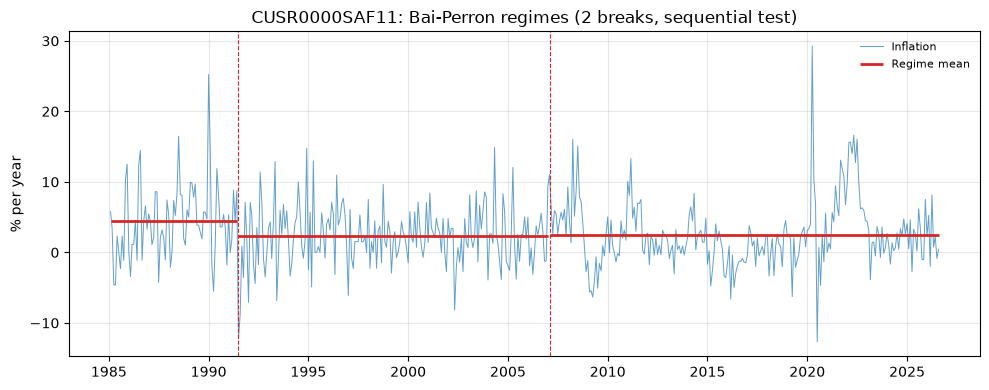

,Breaks,Break dates
Criterion,,
BIC,1,2008-06
LWZ,0,none
Sequential sup-F (5%),2,"1991-07, 2007-02"


,Months,Mean,AR(1),Residual SD
Regime,,,,
1985-02 to 1991-06,77,4.404,0.292,5.091
1991-07 to 2007-01,187,2.263,-0.057,4.251
2007-02 to 2026-08,235,2.527,0.551,3.971


In [12]:
# Bai-Perron: several breaks, dates chosen by the data; regimes shown for the sequential choice
bp_m, bp_seq, bp_choice, bp_regimes, bp_fig = pl.step10_bai_perron(pi, SID)
display(bp_fig); plt.close(bp_fig)
display(bp_choice, bp_regimes.round(3))

**Number of breaks by criterion**
- BIC: 1 break (June 2008)
- LWZ (strictest): no breaks
- Sequential sup-F test (5%): 2 breaks (July 1991, February 2007)
- Mean shift: average inflation fell from 4.4% to 2.3% in 1991, then rose slightly to 2.5% after 2007
- AR change: persistence was near zero in 1991–2007 (−0.06) and rose to 0.55 after 2007
- Residual change: shocks got smaller over time (SD 5.1 → 4.3 → 4.0)
- Agrees with QLR: both put a break in 2007–08, mainly a change in persistence
- No breaks near COVID, the tariffs or the Iran conflict: each regime must cover at least 15% of the sample (about 75 months), so breaks after about 2020 cannot be detected

## Step 8. Forecasts on the hold-out (January 2024 - August 2026)

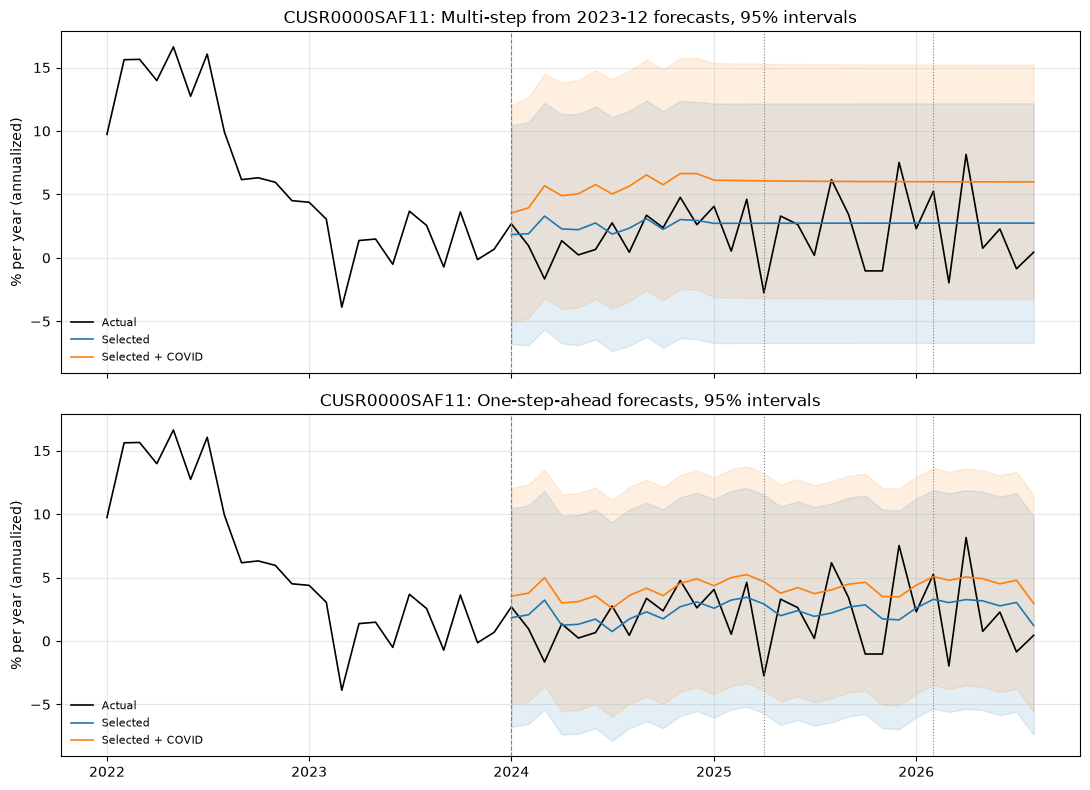

COVID dummy = 3.59, p = 0.000


In [13]:
# Selected model, with and without a COVID dummy, estimated on the training set
multi, one_step, covid_row, fc_fig = pl.step11_forecast(pi, pi_train, order, seasonal, SID)
display(fc_fig); plt.close(fc_fig)
print(f"COVID dummy = {covid_row['COVID dummy']:.2f}, p = {covid_row['p-value']:.3f}")

- Selected model forecasts the average level of inflation well (about 2–3%), but cannot follow the month-to-month swings: actual inflation jumps between about −3% and +8%
- Dummy overshoots the inflation average: it forecasts about 5–6% because it carries the COVID mean shift (+3.6 points, p < 0.001, estimated on 2020–23) into 2024–26, after food inflation had come back down
- 95% intervals are wide (about ±8.5 points, average width about 17), reflecting how noisy monthly inflation is; all 32 actual values fall inside them (100% coverage, Step 9), so the intervals are, if anything, slightly too wide
- Multi-step forecasts flatten toward the model's mean within a few months; one-step forecasts move a little with recent data but stay close to the same level
- After April 2025 actual inflation zigzags more (matching the negative persistence in Step 6), and neither forecast follows it

## Step 9. Forecast evaluation against the benchmarks

,ME,MAE,RMSE,RMSE / RW,MASE
"Selected, one-step",-0.348,2.120,2.712,0.638,0.529
"Selected + COVID, one-step",-2.133,2.752,3.422,0.805,0.686
"Selected, multi-step",-0.622,2.154,2.702,0.636,0.537
"Selected + COVID, multi-step",-3.785,4.024,4.599,1.083,1.004
Random walk,-0.007,3.435,4.249,1.000,0.857
Historical mean,-0.745,2.181,2.721,0.640,0.544


,Mean loss diff,DM (HLN),p-value
"Selected + COVID, one-step",4.352,2.543,0.016
"Selected, multi-step",-0.056,-0.097,0.924
"Selected + COVID, multi-step",13.796,4.366,0.000
Random walk,10.694,3.222,0.003
Historical mean,0.044,0.071,0.944


,RMSE to 2025-03,RMSE from 2025-04,Ratio (after / before)
"Selected, one-step",1.837,3.297,1.794
"Selected + COVID, one-step",2.705,3.948,1.459
"Selected, multi-step",1.881,3.259,1.733
"Selected + COVID, multi-step",3.970,5.090,1.282
Random walk,2.383,5.382,2.259
Historical mean,1.925,3.265,1.696


,95% coverage,Average width
"Selected, one-step",1.0,17.230
"Selected + COVID, one-step",1.0,17.092
"Selected, multi-step",1.0,18.637
"Selected + COVID, multi-step",1.0,18.254


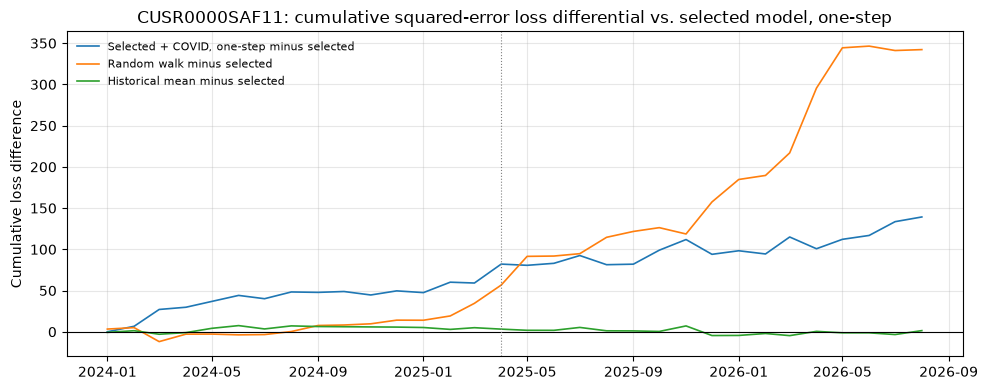

In [14]:
acc, split_rmse, dm, coverage, loss_fig = pl.step12_evaluate(pi, pi_train, multi, one_step, SID)
display(acc.round(3))                 # ME, MAE, RMSE, RMSE relative to the random walk, MASE
display(dm.round(3))                  # Diebold-Mariano: each forecast vs. the selected one-step
display(split_rmse.round(3))          # errors before vs. after the 2025 tariffs date
display(coverage.round(3))            # share of actual values inside the 95% intervals
display(loss_fig); plt.close(loss_fig)

- For almost all the measures the selected model performs the best with historical mean in close second.
- The model with the COVID dummy performs the worst, losing out to baselines random walk and historical mean most of the time.